In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy.stats import randint, uniform
from sklearn.model_selection import train_test_split,KFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier 

from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import ( accuracy_score, classification_report, confusion_matrix, average_precision_score,recall_score,precision_score,f1_score )
import os


In [85]:
df=pd.read_csv("dataset/kidney_disease.csv")
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [86]:
# df["classification"].iloc("ckd\t")

In [87]:
df["classification"] = df["classification"].str.strip()

In [88]:
df["classification"].value_counts()

classification
ckd       250
notckd    150
Name: count, dtype: int64

In [89]:
df=df.drop(columns="id")


In [90]:
df.shape

(400, 25)

In [91]:
df.describe()

,age,bp,sg,al,su,bgr,bu,sc,sod,pot,hemo
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000


In [92]:
obj_cols = df.select_dtypes(include="object").columns
df[obj_cols] = df[obj_cols].apply(lambda s: s.str.strip())

In [93]:
for col in ["pcv", "wc", "rc"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors="coerce")

In [94]:
df.isna().sum()

age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                71
wc                106
rc                131
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

In [95]:
df.duplicated().sum()

np.int64(0)

In [96]:
for i in df.columns:
    print(df[i].value_counts().head())

age
60.0    19
65.0    17
50.0    12
48.0    12
55.0    12
Name: count, dtype: int64
bp
80.0     116
70.0     112
60.0      71
90.0      53
100.0     25
Name: count, dtype: int64
sg
1.020    106
1.010     84
1.025     81
1.015     75
1.005      7
Name: count, dtype: int64
al
0.0    199
1.0     44
3.0     43
2.0     43
4.0     24
Name: count, dtype: int64
su
0.0    290
2.0     18
3.0     14
4.0     13
1.0     13
Name: count, dtype: int64
rbc
normal      201
abnormal     47
Name: count, dtype: int64
pc
normal      259
abnormal     76
Name: count, dtype: int64
pcc
notpresent    354
present        42
Name: count, dtype: int64
ba
notpresent    374
present        22
Name: count, dtype: int64
bgr
99.0     10
100.0     9
93.0      9
107.0     8
117.0     6
Name: count, dtype: int64
bu
46.0    15
25.0    13
19.0    11
40.0    10
15.0     9
Name: count, dtype: int64
sc
1.2    40
1.1    24
0.5    23
1.0    23
0.7    22
Name: count, dtype: int64
sod
135.0    40
140.0    25
141.0    22
139.0    21


In [97]:
df["classification"].value_counts()

classification
ckd       250
notckd    150
Name: count, dtype: int64

In [98]:
num_cols=df.select_dtypes(include=['number']).columns.tolist()
cat_cols=df.select_dtypes(exclude=['number']).columns.tolist()

<Axes: >

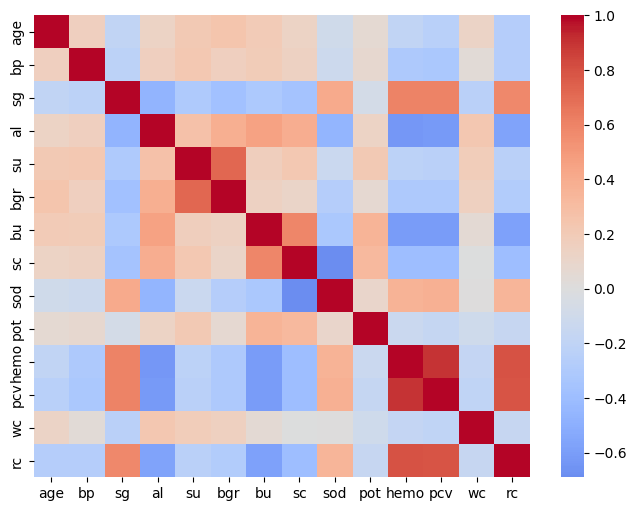

In [99]:
plt.figure(figsize=(8,6))
sns.heatmap(
    df[num_cols].corr(),
    center=0,
    cmap="coolwarm"
)

In [100]:
corr=df[num_cols].corr().abs()

In [101]:
to_drop = [col for col in corr.columns if any((corr[col] > 0.80) & (corr[col] < 1.0) & (corr.index < col))]

In [102]:
df=df.drop(columns=to_drop)

In [103]:
# for i in num_cols:
#     plt.figure(figsize=(7,8))
#     sns.boxplot(df[i])
#     plt.show()

In [104]:
X=df.drop(columns=["classification"])
y=df["classification"]

In [105]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.18,
    random_state=42,
    stratify=y
)

In [106]:
num_cols=X_train.select_dtypes(include=['number']).columns.tolist()
cat_cols=X_train.select_dtypes(exclude=['number']).columns.tolist()

num_pipe=Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("scalar", StandardScaler())
        
    ]
)
cat_pipe=Pipeline(
    [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohc", OneHotEncoder(handle_unknown="ignore"))
    ]
)
preprocess=ColumnTransformer(
    transformers=[
        ("num",num_pipe,num_cols),
        ("cat",cat_pipe,cat_cols)
    ]

)

In [107]:
base_model=Pipeline(
    [
        
        ("preprocess",preprocess),
        ("model", LogisticRegression())

    ]
)

In [108]:
base_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['ckd','notckd']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['age','bp','sg',...,'appet','pe','ane']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns tha

In [109]:
train_pred_base=base_model.predict(X_train)
test_pred_base=base_model.predict(X_test)

In [110]:
print(classification_report(y_train,train_pred_base))
print("*"*100)
print(classification_report(y_test,test_pred_base))

              precision    recall  f1-score   support

         ckd       1.00      1.00      1.00       205
      notckd       1.00      1.00      1.00       123

    accuracy                           1.00       328
   macro avg       1.00      1.00      1.00       328
weighted avg       1.00      1.00      1.00       328

****************************************************************************************************
              precision    recall  f1-score   support

         ckd       1.00      1.00      1.00        45
      notckd       1.00      1.00      1.00        27

    accuracy                           1.00        72
   macro avg       1.00      1.00      1.00        72
weighted avg       1.00      1.00      1.00        72



In [111]:
models={
    "Decision_tree": DecisionTreeClassifier(random_state=42),
    "Support_vector": SVC(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier()
}

In [112]:
k=5
cv=KFold(n_splits=k,shuffle=True,random_state=42)

In [113]:
final_model=Pipeline(
    [
        ("transform",preprocess),
        ("model", RandomForestClassifier( random_state=42,
                                          bootstrap= True,
                                            ccp_alpha=np.float64(0.00046124850082831517),
                                            max_depth= 5,
                                            max_features= 0.3,
                                            max_samples= np.float64(0.7399513401003394),
                                            min_samples_leaf=19,
                                            min_samples_split= 37,
                                            n_estimators= 1099,
                                            class_weight="balanced"))
]
)

In [114]:
final_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transform', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['ckd','notckd']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['age','bp','sg',...,'appet','pe','ane']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns that

In [115]:
y_pred_train=final_model.predict(X_train)

y_pred_test=final_model.predict(X_test)

In [116]:
print(classification_report(y_train,y_pred_train))
print("*"*100)
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

         ckd       0.99      0.98      0.98       205
      notckd       0.96      0.98      0.97       123

    accuracy                           0.98       328
   macro avg       0.98      0.98      0.98       328
weighted avg       0.98      0.98      0.98       328

****************************************************************************************************
              precision    recall  f1-score   support

         ckd       0.96      0.98      0.97        45
      notckd       0.96      0.93      0.94        27

    accuracy                           0.96        72
   macro avg       0.96      0.95      0.96        72
weighted avg       0.96      0.96      0.96        72



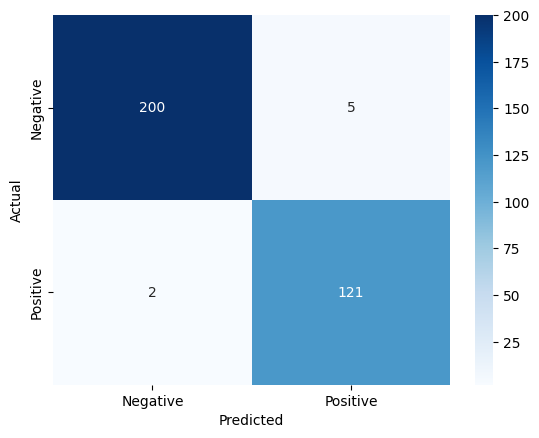

In [117]:
cm = confusion_matrix(y_train, y_pred_train)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Negative", "Positive"], 
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

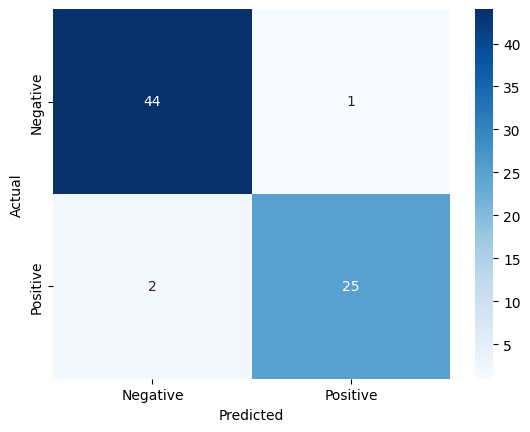

In [118]:
cm = confusion_matrix(y_test, y_pred_test)


sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Negative", "Positive"], 
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()